# Model 2073 — Rolling-Window Stability

#### **MScFE 690 Capstone -Group 17843**

**Authors**: Edgar NAVA-edgar.nava@grovewm.com & Celestin NYANDWI-celestinnyandwi48@gmail.com

Apply the unchanged Model 2073 to synthetic SVXY −1x across overlapping windows of 753 trading sessions (approximately three years), advancing one session at a time. Each window starts with a fresh $100,000 account and is compared with buy and hold.

Notebook **11** supports Section **4.6** of the **Extended Capstone Research Report**.

## 1. Data and settings

Use Development and Validation only: **4 October 2011–29 December 2023**. The first window ends on 1 October 2014; the last is exactly Validation, **4 January 2021–29 December 2023**. The input paths follow `config.json`, as in Notebook 08. Run all cells in order; tables and the chart are saved in `Results/`.

Costs are $0.005 per share and 0.10% adverse slippage per side. Fractional shares are allowed, cash earns no interest, and signals and execution use the same Close. Each window resets positions, the exit flag and the trailing stop; only the preceding VIX state comes from earlier history. Open positions are valued at the last Close without a forced sale.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from IPython.display import display

%matplotlib inline

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.json").is_file()), None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the project folder.")
CONFIG = json.loads((PROJECT_ROOT / "config.json").read_text(encoding="utf-8"))
RAW_DATA_DIR = PROJECT_ROOT / CONFIG["raw_data_dir"]
PROCESSED_DATA_DIR = PROJECT_ROOT / CONFIG["processed_data_dir"]
RESULTS_DIR = Path.cwd() / "Results"
RESULTS_DIR.mkdir(exist_ok=True)
START, END = "2011-10-04", "2023-12-29"
WINDOW_SESSIONS, STEP_SESSIONS = 753, 1
INITIAL_CASH = 100_000.0
COMMISSION_PER_SHARE, SLIPPAGE_PCT = 0.005, 0.001
SESSIONS_PER_YEAR, ANNUAL_RISK_FREE_RATE = 252, 0.0
STATE_THRESHOLDS = [17.5, 22.540001, 28.805999000000003, 37.810001]
RULES = {
    "C2": {"vix_min": 23.0, "cash_fraction": 0.15,
           "target_nav": 0.70, "trailing_stop_pct": 0.20},
    "C3": {"vix_max": 28.0, "cash_fraction": 0.10,
           "invested_cash_fraction": 0.50, "trailing_stop_pct": 0.40},
    "V2": {"vix_min": 19.0}, "V3": {"vix_max": 15.0},
}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "figure.dpi": 120})
def blue_table(frame, caption, formatter=None):
    return (frame.style.format(formatter, na_rep="N/A")
        .set_caption(caption)
        .set_table_styles([
            {"selector": "caption", "props": [("text-align", "left"),
                ("color", "#255c80"), ("font-size", "16px"), ("padding", "8px 0")]},
            {"selector": "th", "props": [("background-color", "#255c80"),
                ("color", "white"), ("text-align", "left"), ("padding", "9px 12px")]},
            {"selector": "td", "props": [("padding", "9px 12px"), ("text-align", "right")]},
            {"selector": "tbody tr:nth-child(even)",
             "props": [("background-color", "#edf3f7")]},
            {"selector": "table", "props": [("border-collapse", "collapse")]},
        ]))
vix = (pd.read_csv(RAW_DATA_DIR / "VIX_data.csv", parse_dates=["Date"])
       .set_index("Date").sort_index().loc[:END, ["Close"]])
etf = (pd.read_csv(PROCESSED_DATA_DIR / "SVXY_synth-ONEx.csv", parse_dates=["Date"])
       .set_index("Date").sort_index().loc[START:END, ["Close"]])
vix["State"] = np.searchsorted(STATE_THRESHOLDS, vix.Close.to_numpy(), side="left") + 1
vix["Previous_state"] = vix.State.shift(1)
prices = etf.join(vix.rename(columns={"Close": "VIX_Close"}), how="left")
if (prices.empty or prices.isna().any().any() or not prices.index.is_unique
        or not vix.index.is_unique or not np.isfinite(prices.to_numpy()).all()
        or not prices[["Close", "VIX_Close"]].gt(0).all().all()):
    raise ValueError("Check the input dates and aligned VIX/SVXY observations.")
window_starts = range(0, len(prices) - WINDOW_SESSIONS + 1, STEP_SESSIONS)
print(f"{len(window_starts):,} windows of {WINDOW_SESSIONS} sessions; "
      f"{STEP_SESSIONS}-session step.")


2,328 windows of 753 sessions; 1-session step.


## 2. Model 2073

Use the same C2/C3 entries, V1/V2/V3 exits, allocations and 20%/40% trailing stops as `08-Model_2073_SVXY-ONEx.ipynb`. Sell signals take priority; an actual purchase resets the trailing-stop peak. No parameters are re-estimated.

In [2]:
def finish_account(account):
    account = account.copy()
    account["Position_value"] = account.Units * account.Close
    account["Equity"] = account.Cash + account.Position_value
    account["Daily_return"] = account.Equity.pct_change(fill_method=None)
    account.loc[account.index[0], "Daily_return"] = account.Equity.iloc[0] / INITIAL_CASH - 1
    account["Drawdown"] = account.Equity / account.Equity.cummax().clip(lower=INITIAL_CASH) - 1
    account["Exposure"] = account.Position_value / account.Equity
    return account


def run_buy_and_hold(data):
    account = data[["Close"]].copy()
    first_close = float(account.Close.iloc[0])
    execution_price = first_close * (1 + SLIPPAGE_PCT)
    units = INITIAL_CASH / (execution_price + COMMISSION_PER_SHARE)
    account["Cash"], account["Units"] = 0.0, units
    account["Commission"], account["Slippage_cost"] = 0.0, 0.0
    account.loc[account.index[0], "Commission"] = units * COMMISSION_PER_SHARE
    account.loc[account.index[0], "Slippage_cost"] = units * first_close * SLIPPAGE_PCT
    return finish_account(account)


def performance(account):
    final = float(account.Equity.iloc[-1])
    years = (account.index[-1] - account.index[0]).days / 365.25
    cagr = (final / INITIAL_CASH) ** (1 / years) - 1
    max_drawdown = float(account.Drawdown.min())
    daily_rf = (1 + ANNUAL_RISK_FREE_RATE) ** (1 / SESSIONS_PER_YEAR) - 1
    excess = account.Daily_return - daily_rf
    volatility = float(excess.std(ddof=1))
    return pd.Series({
        "Initial equity ($)": INITIAL_CASH,
        "Final equity ($)": final,
        "Total profit ($)": final - INITIAL_CASH,
        "Total return": final / INITIAL_CASH - 1,
        "Annualized return (CAGR)": cagr,
        "Sharpe ratio": np.sqrt(SESSIONS_PER_YEAR) * excess.mean() / volatility
            if volatility > 0 else np.nan,
        "Calmar ratio": cagr / abs(max_drawdown)
            if np.isfinite(cagr) and max_drawdown < 0 else np.nan,
        "Drawdown at final date": float(account.Drawdown.iloc[-1]),
        "Maximum drawdown": max_drawdown,
    })

def run_model(data):
    cash, units, flag = INITIAL_CASH, 0.0, 0
    peak_close = active_stop_pct = np.nan
    records, orders = [], []
    cash_tolerance = max(1.0, INITIAL_CASH) * 1e-12

    for row in data.itertuples():
        date = row.Index
        price, vix_close = float(row.Close), float(row.VIX_Close)
        state, previous = int(row.State), int(row.Previous_state)
        equity_before = cash + units * price
        side, rule_id = None, ""
        target, execution_price = np.nan, np.nan
        commission, slippage_cost = 0.0, 0.0

        # Existing stops take priority over all other signals.
        if units > 0:
            peak_close = max(peak_close, price)
            if price <= peak_close * (1 - active_stop_pct):
                side, rule_id = "SELL", "V1"

        if side is None and units > 0:
            if state == 1 and previous in (2, 3, 4, 5):
                flag = 1
            if flag == 1:
                if previous == 1 and state > 1 and vix_close > RULES["V2"]["vix_min"]:
                    side, rule_id = "SELL", "V2"
                elif state == 1 and vix_close < RULES["V3"]["vix_max"]:
                    side, rule_id = "SELL", "V3"

        if side == "SELL":
            quantity = units
            execution_price = price * (1 - SLIPPAGE_PCT)
            commission = quantity * COMMISSION_PER_SHARE
            slippage_cost = quantity * price * SLIPPAGE_PCT
            cash += quantity * execution_price - commission
            units, flag = 0.0, 0
            peak_close = active_stop_pct = np.nan
        else:
            if previous == 2 and state == 3 and vix_close > RULES["C2"]["vix_min"]:
                rule_id = "C2"
                target = RULES[rule_id]["target_nav"] if units > 0 else RULES[rule_id]["cash_fraction"]
            elif previous == 4 and state == 3 and vix_close < RULES["C3"]["vix_max"]:
                rule_id = "C3"
                target = RULES[rule_id]["invested_cash_fraction"] if units > 0 else RULES[rule_id]["cash_fraction"]

            if np.isfinite(target):
                execution_price = price * (1 + SLIPPAGE_PCT)
                all_in_price = execution_price + COMMISSION_PER_SHARE
                if units == 0 or rule_id == "C3":
                    quantity = target * cash / all_in_price
                else:
                    # C2 targets position value / NAV after transaction costs.
                    gap = max(0.0, target * equity_before - units * price)
                    quantity = min(cash / all_in_price,
                        gap / (price + target * (price * SLIPPAGE_PCT + COMMISSION_PER_SHARE)))

                if quantity * all_in_price > cash_tolerance:
                    side = "BUY"
                    commission = quantity * COMMISSION_PER_SHARE
                    slippage_cost = quantity * price * SLIPPAGE_PCT
                    cash -= quantity * execution_price + commission
                    units += quantity
                    active_stop_pct = RULES[rule_id]["trailing_stop_pct"]
                    peak_close = price

        # Remove floating-point residue without allowing borrowing.
        if -cash_tolerance <= cash < 0:
            cash = 0.0
        if cash < 0 or units < 0:
            raise ArithmeticError(f"Negative cash or units at {date}.")
        if units == 0:
            flag = 0
        stop = peak_close * (1 - active_stop_pct) if units > 0 else np.nan

        if side is not None:
            orders.append({
                "Date": date, "Side": side, "Rule ID": rule_id,
                "Close": price, "Execution price": execution_price, "Units": quantity,
                "Commission ($)": commission, "Slippage ($)": slippage_cost,
                "Cash after": cash, "Units after": units,
            })
        records.append({
            "Date": date, "Close": price, "VIX_Close": vix_close,
            "State": state, "Previous_state": previous,
            "Cash": cash, "Units": units, "Commission": commission,
            "Slippage_cost": slippage_cost, "Peak_close": peak_close,
            "Stop_threshold": stop, "Trailing_stop_pct": active_stop_pct,
            "Flag": flag, "Action": side or "HOLD", "Rule ID": rule_id,
        })

    account = finish_account(pd.DataFrame(records).set_index("Date"))
    order_columns = ["Date", "Side", "Rule ID", "Close", "Execution price", "Units",
                     "Commission ($)", "Slippage ($)", "Cash after", "Units after"]
    return account, pd.DataFrame(orders, columns=order_columns)

## 3. Window results

Calculate all 2,328 windows from fresh accounts. CAGR uses elapsed calendar days; Sharpe uses 252 sessions and a zero risk-free rate. MDD is a positive loss magnitude, so lower is better. The tables show the first and last three windows and a summary of all windows; the CSV contains every window.

The windows overlap and use data involved in model selection. This is a descriptive stability study, not an independent out-of-sample test. “Model better” is the fraction of comparable windows with higher CAGR or Sharpe, or lower MDD.

In [3]:
rows = []
for window_id, offset in enumerate(window_starts, 1):
    data = prices.iloc[offset:offset + WINDOW_SESSIONS]
    account, orders = run_model(data)
    benchmark = run_buy_and_hold(data)
    m, bh = performance(account), performance(benchmark)
    row = {"Window_id": window_id, "Start": data.index[0], "End": data.index[-1],
           "Sessions": len(data), "Calendar_days": (data.index[-1] - data.index[0]).days}
    for label, values in [("Strategy", m), ("Benchmark", bh)]:
        row.update({f"{label}_CAGR": values["Annualized return (CAGR)"],
                    f"{label}_Max_drawdown": abs(values["Maximum drawdown"]),
                    f"{label}_Sharpe": values["Sharpe ratio"],
                    f"{label}_Total_return": values["Total return"],
                    f"{label}_Final_equity": values["Final equity ($)"]})
    row.update({"Strategy_Average_exposure": account.Exposure.mean(),
                "Strategy_Max_exposure": account.Exposure.max(),
                "Buy_orders": int(orders.Side.eq("BUY").sum()),
                "Sell_orders": int(orders.Side.eq("SELL").sum())})
    rows.append(row)
rolling = pd.DataFrame(rows)
rolling.to_csv(RESULTS_DIR / "rolling_window_metrics.csv", index=False, date_format="%Y-%m-%d")
columns = ["Start", "End", "Strategy_CAGR", "Benchmark_CAGR", "Strategy_Max_drawdown",
           "Benchmark_Max_drawdown", "Strategy_Sharpe", "Benchmark_Sharpe"]
shown = pd.concat([rolling[columns].head(3), rolling[columns].tail(3)]).set_index(["Start", "End"])
shown.index = pd.MultiIndex.from_arrays(
    [shown.index.get_level_values(0).strftime("%Y-%m-%d"),
     shown.index.get_level_values(1).strftime("%Y-%m-%d")], names=["Start", "End"])
shown.columns = ["Model CAGR", "B&H CAGR", "Model MDD", "B&H MDD", "Model Sharpe", "B&H Sharpe"]
display(blue_table(shown, "First and last three windows",
    {c: "{:.3f}" if "Sharpe" in c else "{:.2%}" for c in shown.columns}))

summary_rows = []
for field, label in [("CAGR", "CAGR"), ("Max_drawdown", "Maximum drawdown"), ("Sharpe", "Sharpe ratio")]:
    strategy, benchmark = rolling[f"Strategy_{field}"], rolling[f"Benchmark_{field}"]
    valid = strategy.notna() & benchmark.notna()
    better = strategy[valid] < benchmark[valid] - 1e-12 if field == "Max_drawdown" else strategy[valid] > benchmark[valid] + 1e-12
    summary_rows.append({"Metric": label, "Strategy_median": strategy.median(),
        "Benchmark_median": benchmark.median(), "Strategy_min": strategy.min(),
        "Strategy_max": strategy.max(), "Benchmark_min": benchmark.min(),
        "Benchmark_max": benchmark.max(), "Comparable_windows": int(valid.sum()),
        "Strategy_better_fraction": better.mean()})
summary = pd.DataFrame(summary_rows).set_index("Metric")
summary.to_csv(RESULTS_DIR / "stability_summary.csv")
shown = pd.DataFrame(index=summary.index)
for label, row in summary.iterrows():
    fmt = (lambda x: f"{x:.3f}") if label == "Sharpe ratio" else (lambda x: f"{x:.2%}")
    shown.loc[label, "Model median"] = fmt(row.Strategy_median)
    shown.loc[label, "B&H median"] = fmt(row.Benchmark_median)
    shown.loc[label, "Model range"] = f"{fmt(row.Strategy_min)} to {fmt(row.Strategy_max)}"
    shown.loc[label, "B&H range"] = f"{fmt(row.Benchmark_min)} to {fmt(row.Benchmark_max)}"
    shown.loc[label, "Model better"] = f"{row.Strategy_better_fraction:.2%}"
display(blue_table(shown, "Summary across all rolling windows"))


,,Model CAGR,B&H CAGR,Model MDD,B&H MDD,Model Sharpe,B&H Sharpe
Start,End,,,,,,
2011-10-04,2014-10-01,18.29%,91.25%,15.92%,38.97%,0.952,1.395
2011-10-05,2014-10-02,18.29%,86.98%,15.92%,38.97%,0.952,1.359
2011-10-06,2014-10-03,18.29%,89.39%,15.92%,38.97%,0.952,1.380
2020-12-30,2023-12-27,31.82%,62.93%,31.49%,56.58%,0.942,1.071
2020-12-31,2023-12-28,31.82%,63.05%,31.49%,56.58%,0.942,1.072
2021-01-04,2023-12-29,31.92%,68.17%,31.49%,56.58%,0.942,1.116


,Model median,B&H median,Model range,B&H range,Model better
Metric,,,,,
CAGR,14.93%,24.04%,-1.29% to 52.91%,-39.15% to 96.76%,43.43%
Maximum drawdown,15.17%,67.94%,1.35% to 31.49%,38.97% to 87.93%,100.00%
Sharpe ratio,0.914,0.668,-0.322 to 1.298,-0.177 to 1.473,77.71%


## 4. Rolling-window chart

Each point summarizes the 753-session window ending on the date shown. The three panels compare CAGR, maximum drawdown and Sharpe ratio for Model 2073 and buy and hold.

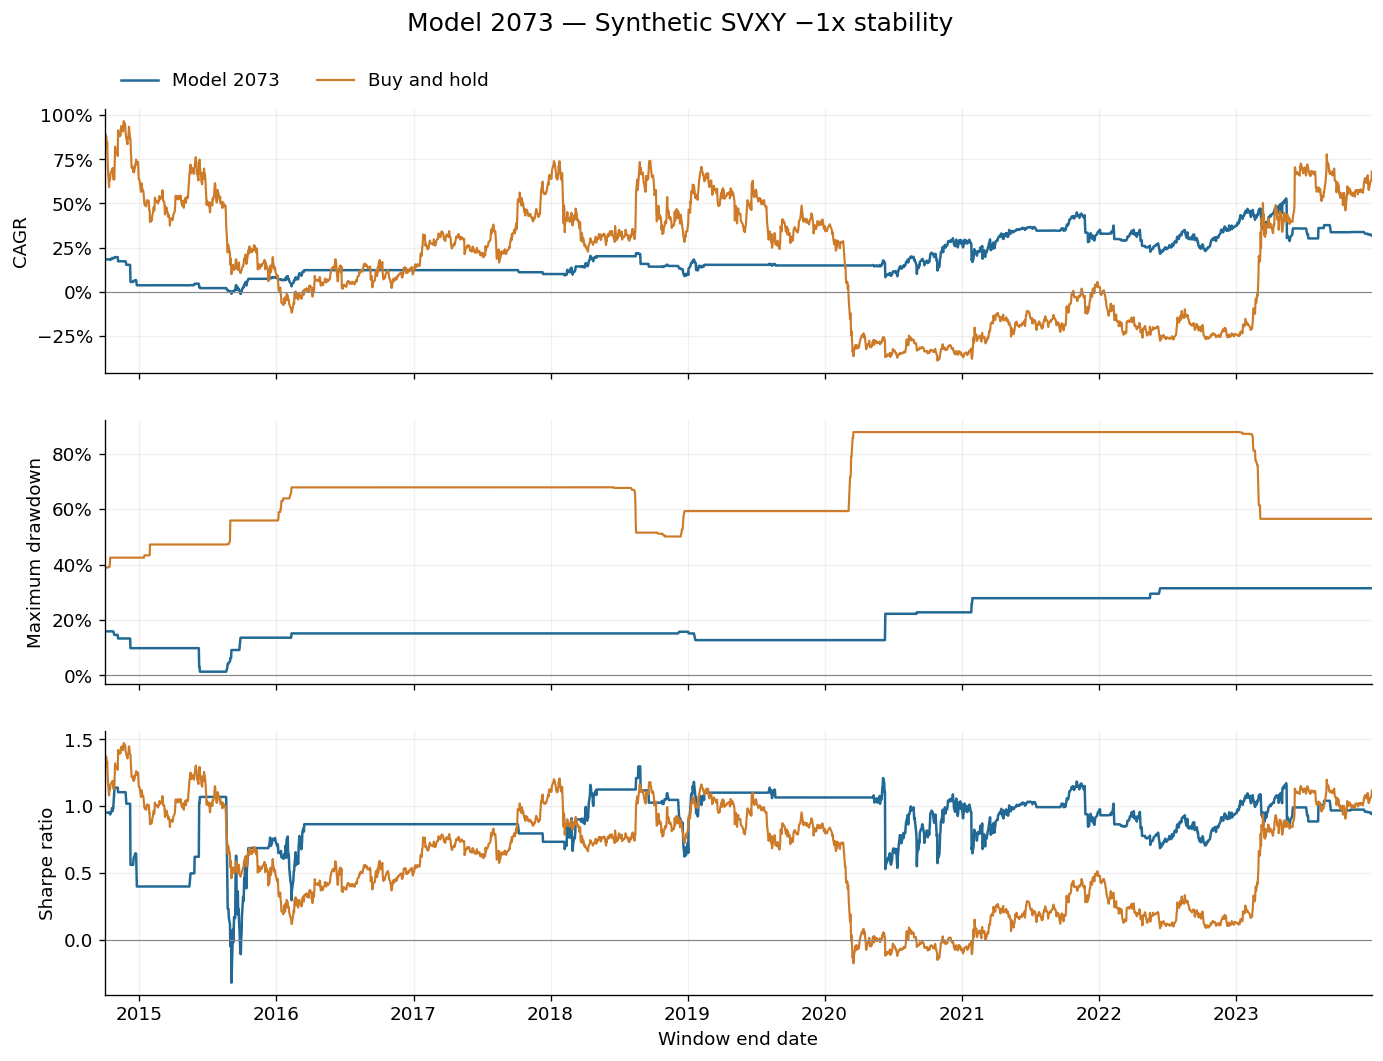

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (field, label) in zip(axes, [("CAGR", "CAGR"), ("Max_drawdown", "Maximum drawdown"), ("Sharpe", "Sharpe ratio")]):
    ax.plot(rolling.End, rolling[f"Strategy_{field}"], color="#226a95", lw=1.5, label="Model 2073")
    ax.plot(rolling.End, rolling[f"Benchmark_{field}"], color="#ce7b29", lw=1.3, label="Buy and hold")
    ax.axhline(0, color="#888888", lw=0.7)
    ax.set_ylabel(label)
    ax.grid(alpha=0.18)
    if field != "Sharpe":
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False)
axes[-1].set_xlabel("Window end date")
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlim(rolling.End.iloc[0], rolling.End.iloc[-1])
fig.suptitle("Model 2073 — Synthetic SVXY −1x stability", y=0.99, fontsize=15)
fig.subplots_adjust(top=0.90, bottom=0.08, left=0.10, right=0.98, hspace=0.18)
fig.savefig(RESULTS_DIR / "rolling_window_stability.png", dpi=180, bbox_inches="tight")
plt.show()
